# Vienna’s Stadtpark — a city landscape built from polygons!

This detailed map transforms one of Vienna’s most iconic green spaces into a colourful mosaic of geometric shapes. From the winding paths and lush green lawns to the blue waters of the Wien River and the park’s ponds, every polygon reveals a different element of the urban landscape. Without labels or conventional map symbols, the intricate geometry speaks for itself, illustrating how nature, architecture, and infrastructure come together to shape this historic park in the heart of Vienna.

#30DayMapChallenge #Day3 #Polygons #Vienna #Stadtpark #GIS #OpenData #Cartography

In [84]:
import matplotlib.pyplot as plt
import geopandas as gpd
from pathlib import Path

MAP_PATH = Path.cwd() / "maps"
MAP_PATH.mkdir(exist_ok=True, parents=True)

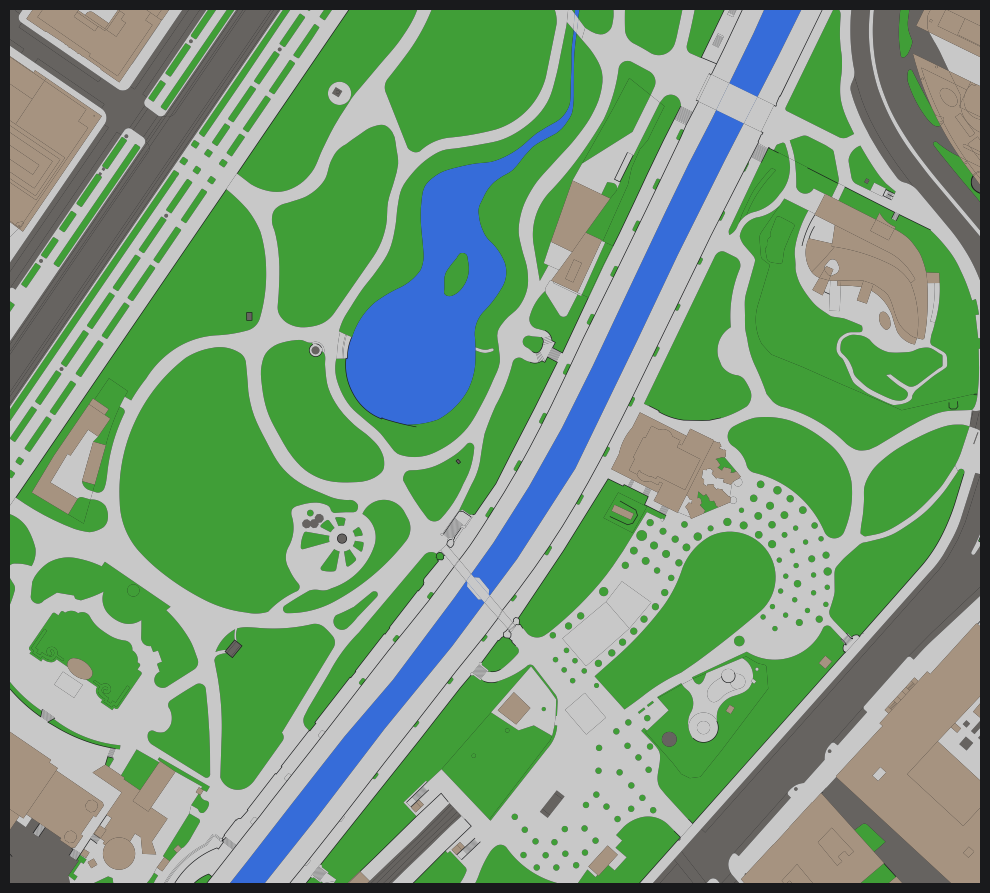

In [86]:
def get_wfs_url(type_name):
    wfs_url = (
        "https://data.wien.gv.at/daten/geo?"
        "service=WFS&"
        "version=2.0.0&"
        "request=GetFeature&"
        f"typeNames={type_name}&"
        "bbox=16.378,48.203,16.385,48.206,EPSG:4326&"
        "srsName=EPSG:31256"
    )
    return wfs_url


gdf = gpd.read_file(get_wfs_url("ogdwien:BAUMKATOGD"))

gdf_w = gpd.read_file(get_wfs_url("ogdwien:FMZKGEWOGD"))
gdf_g2 = gpd.read_file(get_wfs_url("ogdwien:FMZKGRUEN2OGD"))
gdf_v1 = gpd.read_file(get_wfs_url("ogdwien:FMZKVERKEHR1OGD"))
gdf_v2 = gpd.read_file(get_wfs_url("ogdwien:FMZKVERKEHR2OGD"))
gdf_geb = gpd.read_file(get_wfs_url("ogdwien:FMZKGEBOGD"))

fig, ax = plt.subplots(figsize=(10, 10))

gdf_w.plot(ax=ax, edgecolor="none", linewidth=0.0)
gdf_g2.plot(ax=ax, edgecolor="none", color="#409E37", linewidth=0.0)
gdf_v1.plot(ax=ax, edgecolor="none", color="#666360", linewidth=0.0)
gdf_v2.plot(ax=ax, edgecolor="none", color="#c8c8c8", linewidth=0.0)
gdf_geb.plot(ax=ax, edgecolor="none", color="#A69380", linewidth=0.0)

xmin, ymin, xmax, ymax = gdf.total_bounds

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_axis_off()

plt.tight_layout()
plt.savefig(Path(MAP_PATH, "map03.png"), dpi=300, facecolor="white", bbox_inches="tight")